# Logistic regression applied to the British Crime Survey

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn import metrics

Example from Tarling, R. (2009) Statistical modelling for social researchers. Routledge.

Data of the British Crime Survey 2000. We want to explain if a person was victim of a car crime (`victcar`) with characteristics of the person and of the area where they live. All the covariates are categorical.

| Variable | Description | Levels |
|---|---|---|
| `rubbcomm` | How common: litter or rubbish lying around in the immediate area | Very common, Fairly common, Not very common, Not at all common |
| `vandcomm` | How common: vandalism, graffiti or deliberate damage to property | same |
| `poorhou` | How common: homes in poor conditions | same |
| `sex` | Sex | Male, Female |
| `agegrp` | Age (grouped) | 16-19, 20-24, 25-34, 35-44, 45-54, 55-64, 65-74, 75-84, 85 and over |
| `marst` | Marital status | Single, Married and living with husband/wife, Married and separated, Divorced, Widowed |
| `educat2` | Highest educational qualification | 8 levels, from higher degree to other qualifications |
| `sc2` | Social class | Not classified, Professional, Managerial, Skilled Non-Manual, Skilled Manual, Semi skilled, Unskilled, Armed Forces |
| `yrsarea` | How long lived in this area | 7 levels, from less than 12 months to 20 years or longer |
| `yrsaddr` | How long lived at this address | same |
| `arealive` | View about this area as a place to live in | A very good place, A fairly good place, Neither good nor bad, A fairly bad place, A very bad place |
| `region` | Standard region | North, Yorks & Humberside, North West, East Midlands, West Midlands, East Anglia, Greater London, South East, South West, Wales |
| `numcarr` | Number of cars (recoded) | 1, 2, 3, 4 or more |
| `ethnicr` | Ethnic group (recoded) | white, BME (Black or minority ethnicity) |
| `tenurer` | Accommodation (recoded) | owner occupied, rented |
| `victcar` | Victim of car crime (the response) | not victim car crime, victim car crime |

The file also has `wcarstol` and `wfromcar` (worried about having the car, or things from the car, stolen), `agegrpr` (age recoded in three groups) and the sampling weights `weighta` and `weightb`, which we do not use.

In [2]:
dat = pd.read_csv('british_crime_survey_2000.csv', dtype={'numcarr': str})
dat.shape

(15081, 22)

In [3]:
# Keep the rows without missing values
dat = dat[~dat.isnull().any(axis=1)]
dat = dat.reset_index(drop=True)

features = ['rubbcomm', 'vandcomm', 'poorhou', 'sex', 'agegrp', 'marst',
            'educat2', 'sc2', 'yrsarea', 'yrsaddr', 'arealive', 'region',
            'numcarr', 'ethnicr', 'tenurer']

X = dat[features]
y = dat['victcar']
n = len(dat)

print('Complete rows:', n)
y.value_counts()

Complete rows: 10002


victcar
not victim car crime    7569
victim car crime        2433
Name: count, dtype: int64

## A first look: proportion of victims by level

Before any model, the proportion of victims in each level of some of the covariates.

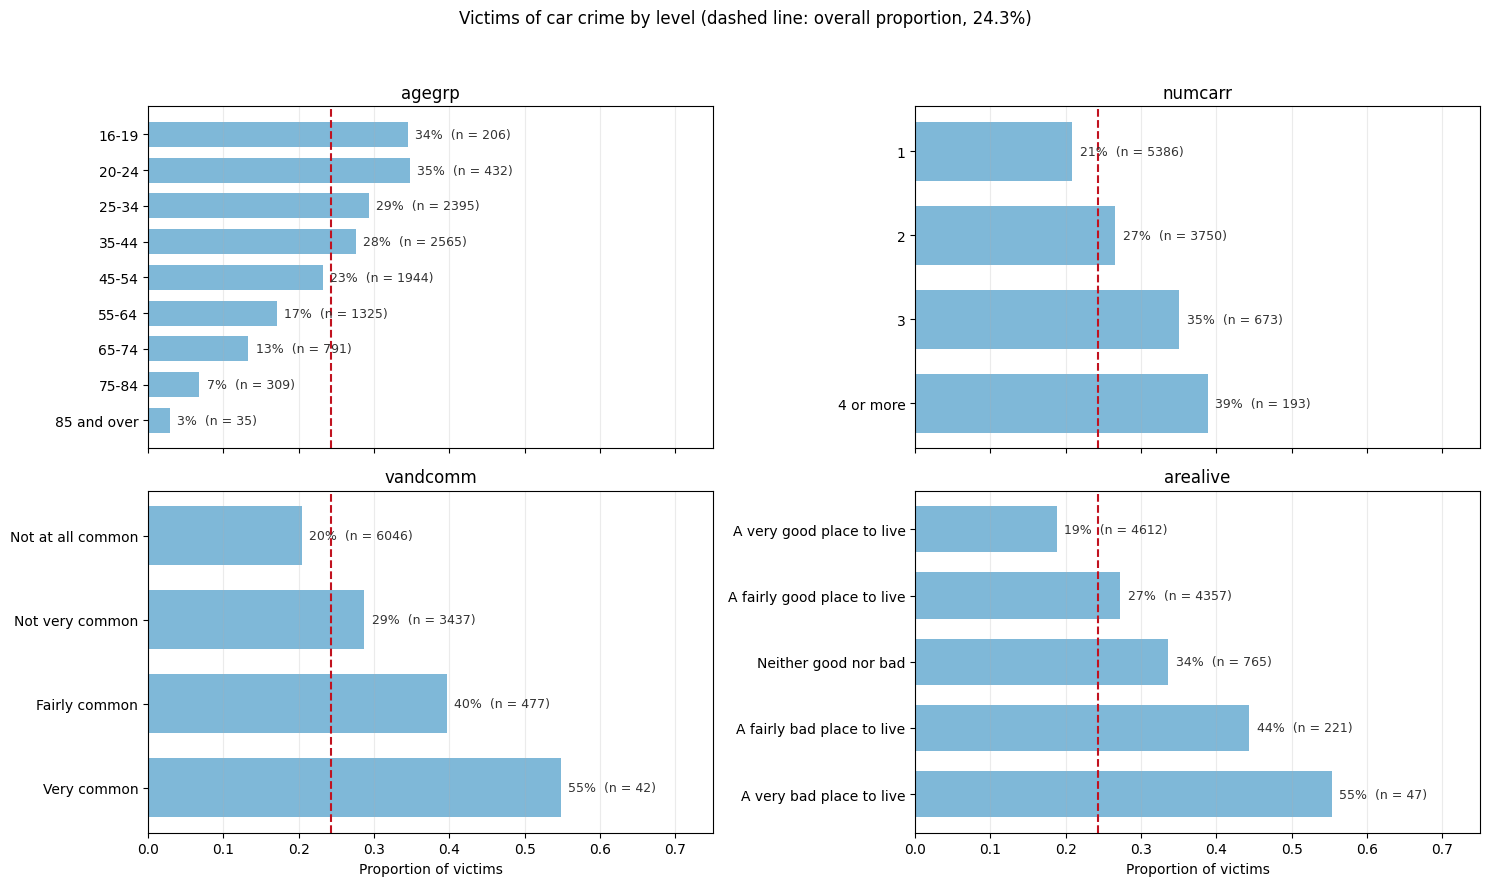

In [4]:
victim = (y == 'victim car crime').to_numpy()
overall = victim.mean()

orders = {
    'agegrp': ['16-19', '20-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-84', '85 and over'],
    'numcarr': ['1', '2', '3', '4 or more'],
    'vandcomm': ['Not at all common', 'Not very common', 'Fairly common', 'Very common'],
    'arealive': ['A very good place to live', 'A fairly good place to live', 'Neither good nor bad',
                 'A fairly bad place to live', 'A very bad place to live'],
}

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, (variable, levels) in zip(axes.ravel(), orders.items()):
    rates = [victim[(X[variable] == level).to_numpy()].mean() for level in levels]
    counts = [(X[variable] == level).sum() for level in levels]
    ax.barh(range(len(levels)), rates, color='#7fb8d8', height=0.7)
    ax.axvline(overall, ls='--', color='#c1121f', lw=1.5)
    for i, (rate, count) in enumerate(zip(rates, counts)):
        ax.text(rate + 0.01, i, f'{100*rate:.0f}%  (n = {count})', va='center', fontsize=9, color='#333333')
    ax.set_yticks(range(len(levels)), levels)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.75)
    ax.set_title(variable)
    ax.grid(True, axis='x', alpha=0.25)
for ax in axes[1]:
    ax.set_xlabel('Proportion of victims')
fig.suptitle(f'Victims of car crime by level (dashed line: overall proportion, {100*overall:.1f}%)')
fig.tight_layout(rect=(0, 0, 1, 0.95))

## Logistic regression with sklearn

`OneHotEncoder` creates one indicator variable for each level. We drop one level of each covariate, which becomes the reference level: with an indicator for every level the columns add up to the intercept and the coefficients are not identifiable. As reference we take the most frequent level of each covariate.

In [5]:
reference = {feature: X[feature].value_counts().idxmax() for feature in features}

enc = OneHotEncoder(drop=[reference[feature] for feature in features], handle_unknown='ignore')
enc.fit(X)

pd.Series(reference, name='reference level').to_frame()

,reference level
rubbcomm,Not at all common
vandcomm,Not at all common
poorhou,Not at all common
sex,Male
agegrp,35-44
marst,Married and living with HusbWife
educat2,O level/GCSE grade A-C/SCE Standard/Ordi
sc2,"Managerial 1,2,13"
yrsarea,20 years or longer
yrsaddr,10 years but less than 20 years


In [6]:
X_with_dummies = enc.transform(X)

# Logistic Regression
logreg = LogisticRegression(penalty=None, tol=1e-10, max_iter=20000)
logreg.fit(X_with_dummies, y)

accuracy_reg_log = logreg.score(X_with_dummies, y)
print('Coefficients:', X_with_dummies.shape[1] + 1)
print('Accuracy:    ', accuracy_reg_log)

Coefficients: 67
Accuracy:     0.7623475304939012


### How good is the classifier?

The accuracy looks good, but 76% of the people were not victims: a "classifier" that always answers *not victim* has almost the same accuracy. The confusion matrix shows that the model classifies very few people as victims.

Accuracy of always predicting "not victim": 0.7567


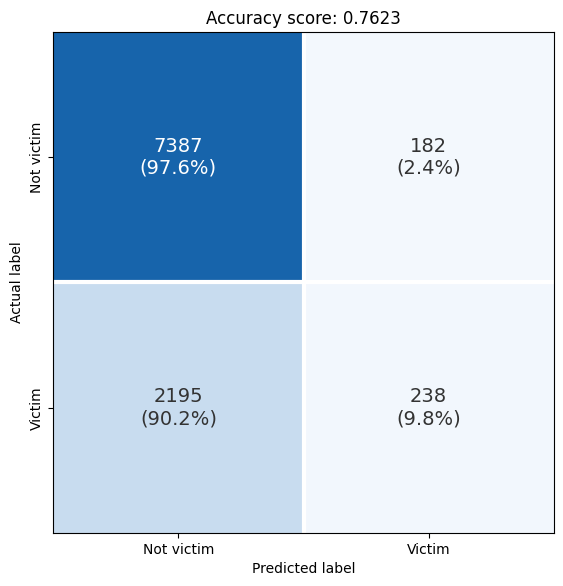

In [7]:
classes = logreg.classes_
confusion_matrix = metrics.confusion_matrix(y_true=y, y_pred=logreg.predict(X_with_dummies), labels=classes)

print(f'Accuracy of always predicting "not victim": {1-overall:.4f}')

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(confusion_matrix, cmap='Blues', vmin=0, vmax=confusion_matrix.max()*1.25)
for i in range(2):
    for j in range(2):
        share = 100*confusion_matrix[i, j]/confusion_matrix[i].sum()
        ax.text(j, i, f'{confusion_matrix[i, j]}\n({share:.1f}%)', ha='center', va='center', fontsize=14,
                color='white' if confusion_matrix[i, j] > 0.6*confusion_matrix.max() else '#333333')
ax.axhline(0.5, color='white', lw=3)
ax.axvline(0.5, color='white', lw=3)
ax.set_xticks([0, 1], ['Not victim', 'Victim'])
ax.set_yticks([0, 1], ['Not victim', 'Victim'], rotation=90, va='center')
ax.set_xlabel('Predicted label')
ax.set_ylabel('Actual label')
ax.set_title(f'Accuracy score: {accuracy_reg_log:.4f}');

The model is more useful to order the people by their risk than to classify them with the threshold 0.5. The estimated probabilities of the victims are higher, but both groups overlap a lot. The peak at zero are the people whose social class is "Not classified": almost none of them was victim of a car crime. The ROC curve shows the proportion of victims detected against the proportion of false alarms for every threshold.

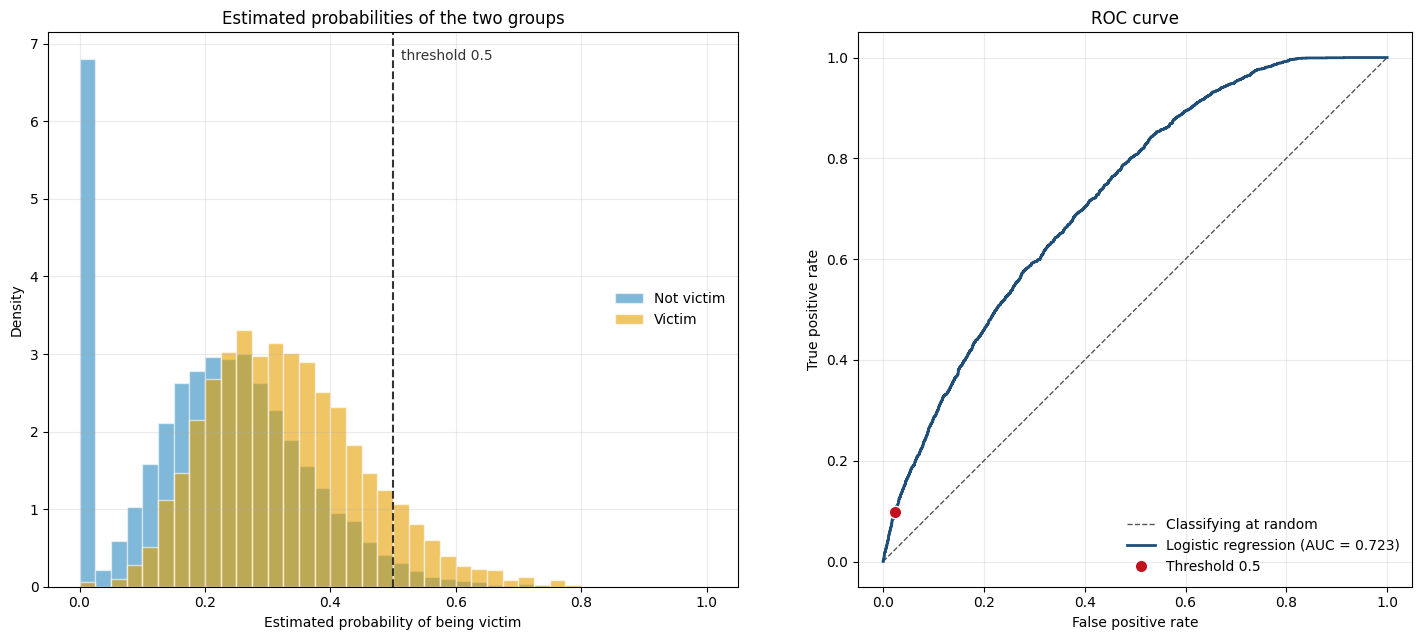

In [8]:
proba = logreg.predict_proba(X_with_dummies)[:, 1]
fpr, tpr, thresholds = metrics.roc_curve(victim, proba)
auc = metrics.roc_auc_score(victim, proba)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

bins = np.linspace(0, 1, 41)
axes[0].hist(proba[~victim], bins=bins, density=True, color='#0072B2', alpha=0.5, edgecolor='white', label='Not victim')
axes[0].hist(proba[victim], bins=bins, density=True, color='#E69F00', alpha=0.6, edgecolor='white', label='Victim')
axes[0].axvline(0.5, ls='--', color='#333333', lw=1.5)
axes[0].annotate('threshold 0.5', (0.5, 0.95), xycoords=('data', 'axes fraction'), xytext=(6, 0),
                 textcoords='offset points', fontsize=10, color='#333333')
axes[0].set_xlabel('Estimated probability of being victim')
axes[0].set_ylabel('Density')
axes[0].set_title('Estimated probabilities of the two groups')
axes[0].legend(loc='center right', frameon=False)

axes[1].plot([0, 1], [0, 1], '--', color='#555555', lw=1, label='Classifying at random')
axes[1].plot(fpr, tpr, color='#1f4e79', lw=2, label=f'Logistic regression (AUC = {auc:.3f})')
i_half = np.argmin(np.abs(thresholds-0.5))
axes[1].plot(fpr[i_half], tpr[i_half], 'o', color='#c1121f', markersize=9, markeredgecolor='white', markeredgewidth=1,
             label='Threshold 0.5')
axes[1].set_aspect('equal')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve')
axes[1].legend(loc='lower right', frameon=False)

for ax in axes:
    ax.grid(True, alpha=0.25)
plt.tight_layout()

In [9]:
not_classified = (X['sc2'] == 'Not classified').to_numpy()
print('People with social class not classified:', not_classified.sum())
print('Victims among them:                     ', victim[not_classified].sum())

People with social class not classified: 1290
Victims among them:                      3


### Prediction for one person

In [10]:
X.iloc[0,]

rubbcomm                          Not at all common
vandcomm                            Not very common
poorhou                           Not at all common
sex                                            Male
agegrp                                        25-34
marst                Single, that is, never married
educat2     First degree (incl. B.Ed); Postgraduate
sc2                        Skilled Manual 8,9,12,14
yrsarea                         less than 12 months
yrsaddr                         less than 12 months
arealive                  A very good place to live
region                                   South East
numcarr                                           1
ethnicr                                       white
tenurer                                      rented
Name: 0, dtype: object

In [11]:
person = X.iloc[[0]]
person_trans = enc.transform(person)

print('Prediction:', logreg.predict(person_trans)[0])
print('Probability of being victim:', logreg.predict_proba(person_trans)[0, 1])

Prediction: not victim car crime
Probability of being victim: 0.24432390756612957


## Interpreting the model: odds ratios

`sklearn` does not give standard errors. With `statsmodels` we fit the same model and get them. The exponential of a coefficient is an odds ratio: how many times the odds of being victim are multiplied with respect to the reference level of that covariate, keeping the rest fixed.

In [12]:
dummy_names = enc.get_feature_names_out(features)
X_sm = sm.add_constant(pd.DataFrame(X_with_dummies.toarray(), columns=dummy_names))

logit = sm.Logit(victim.astype(int), X_sm).fit(disp=False)

print('Largest difference with the coefficients of sklearn:',
      np.max(np.abs(logit.params.to_numpy() - np.r_[logreg.intercept_, logreg.coef_[0]])))

Largest difference with the coefficients of sklearn: 3.976960237217497e-05


In [13]:
odds_ratios = pd.DataFrame({
    'odds ratio': np.exp(logit.params),
    'lower': np.exp(logit.conf_int()[0]),
    'upper': np.exp(logit.conf_int()[1]),
    'z': logit.tvalues,
    'p-value': logit.pvalues}).drop('const')

# The 20 coefficients with the largest |z|
top = odds_ratios.reindex(odds_ratios['z'].abs().sort_values(ascending=False).index).head(20)
top.round(3)

,odds ratio,lower,upper,z,p-value
numcarr_3,2.479,2.046,3.004,9.264,0.000
sc2_Not classified,0.006,0.002,0.019,-8.787,0.000
numcarr_2,1.627,1.453,1.821,8.448,0.000
numcarr_4 or more,3.203,2.303,4.455,6.915,0.000
arealive_A fairly good place to live,1.392,1.249,1.551,5.988,0.000
agegrp_55-64,0.590,0.487,0.715,-5.395,0.000
arealive_A fairly bad place to live,2.139,1.577,2.901,4.889,0.000
agegrp_75-84,0.302,0.187,0.490,-4.860,0.000
arealive_Neither good nor bad,1.513,1.257,1.823,4.367,0.000
agegrp_65-74,0.571,0.441,0.739,-4.260,0.000


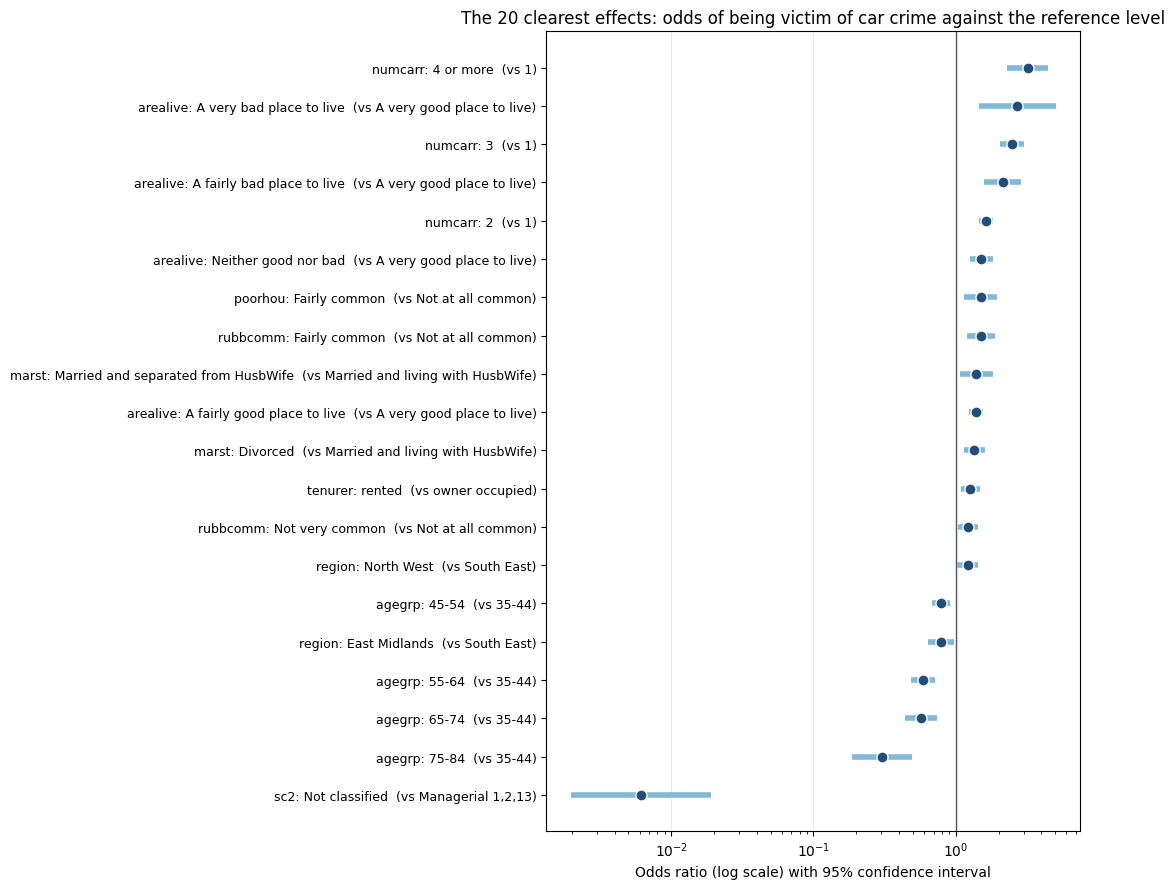

In [14]:
top_plot = top.sort_values('odds ratio')

fig, ax = plt.subplots(figsize=(11, 9))
pos = np.arange(len(top_plot))
ax.axvline(1, color='#555555', lw=1)
ax.hlines(pos, top_plot['lower'], top_plot['upper'], color='#7fb8d8', lw=4)
ax.plot(top_plot['odds ratio'], pos, 'o', color='#1f4e79', markersize=8, markeredgecolor='white', markeredgewidth=1)

labels = []
for name in top_plot.index:
    feature = next(f for f in features if name.startswith(f + '_'))
    labels.append(f'{feature}: {name[len(feature)+1:]}  (vs {reference[feature]})')
ax.set_yticks(pos, labels, fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('Odds ratio (log scale) with 95% confidence interval')
ax.set_title('The 20 clearest effects: odds of being victim of car crime against the reference level')
ax.grid(True, axis='x', alpha=0.25)
plt.tight_layout()

The more cars, the higher the odds of being victim; the odds are also higher for the people who think that their area is a bad place to live, and they decrease with the age. The level "Not classified" of the social class is a special case: with 3 victims among 1290 people its odds ratio is almost zero.